<!-- ## question
--- -->
design a single-phase ($1\phi$), core-type, oil-immersed power transformer having a rated capacity ($Q$) of $2000\text{ kVA}$ ($2000 \times 10^3\text{ VA}$) and operating at a frequency ($f$) of $50\text{ Hz}$. The primary voltage ($V_1$) is $6.6\text{ kV}$ ($6600\text{ V}$) and the secondary voltage ($V_2$) is $415\text{ V}$. The specifications include a maximum core flux density ($B_m$) of $1.5\text{ T}$ and a current density ($\delta$) of $2.5\text{ A/mm}^2$. Additionally, the design constant ($K$) is $0.8$, the window space factor ($K_w$) is $\frac{10}{30 + K V_{HV}} = \frac{10}{30 + 6.6} \approx 0.273$ (noted as $0.28$), the iron stacking factor ($K_i$) is $0.9$, the core factor ($K_c$) is $0.62$, and the window height-to-width ratio ($H_w / W_w$) is $3.0$.

In [ ]:
import femm

# 1. Initialize FEMM
femm.openfemm()
femm.newdocument(0)  # 0 = Magnetics Problem

# 2. Problem Definition (Frequency = 50Hz, Units = millimeters, Planar)
femm.mi_probdef(50, 'millimeters', 'planar', 1e-8, 0, 30)

# 3. Define Materials
femm.mi_addmaterial('Air', 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0)
femm.mi_addmaterial('Copper', 1, 1, 0, 0, 58, 0, 0, 1, 0, 0, 0)
femm.mi_addmaterial('Silicon Steel Core', 1500, 1500, 0, 0, 0, 0, 0, 0.9, 0, 0, 0)
femm.mi_addmaterial('Transformer Oil', 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0)
femm.mi_addmaterial('Steel Tank', 1000, 1000, 0, 0, 4.5, 0, 0, 1, 0, 0, 0)

# 4. Define Circuits / Windings (Primary & Secondary Currents)
I1 = 303.0   # Primary Current (A)[cite: 1]
I2 = 4819.0  # Secondary Current (A)[cite: 1]
femm.mi_addcircprop('Primary_Winding', I1, 1)
femm.mi_addcircprop('Secondary_Winding', -I2, 1)

# 5. Core & Window Dimensions (in mm)[cite: 1]
core_w = 416    
win_w  = 180    
win_h  = 540    
yoke_h = 416    

x0, x1, x2, x3 = 0, core_w, core_w + win_w, 2 * core_w + win_w
y0, y1, y2, y3 = 0, yoke_h, yoke_h + win_h, 2 * yoke_h + win_h

# 6. Draw Core Outer Boundary
femm.mi_addnode(x0, y0)
femm.mi_addnode(x3, y0)
femm.mi_addnode(x3, y3)
femm.mi_addnode(x0, y3)

femm.mi_addsegment(x0, y0, x3, y0)
femm.mi_addsegment(x3, y0, x3, y3)
femm.mi_addsegment(x3, y3, x0, y3)
femm.mi_addsegment(x0, y3, x0, y0)

# 7. Draw Core Window (Opening)
femm.mi_addnode(x1, y1)
femm.mi_addnode(x2, y1)
femm.mi_addnode(x2, y2)
femm.mi_addnode(x1, y2)

femm.mi_addsegment(x1, y1, x2, y1)
femm.mi_addsegment(x2, y1, x2, y2)
femm.mi_addsegment(x2, y2, x1, y2)
femm.mi_addsegment(x1, y2, x1, y1)

# 8. Split Window into Two Halves (Secondary = Left, Primary = Right)
mid_win_x = x1 + (win_w / 2.0)
femm.mi_addnode(mid_win_x, y1)
femm.mi_addnode(mid_win_x, y2)
femm.mi_addsegment(mid_win_x, y1, mid_win_x, y2)

# 9. Draw Transformer Inner Tank Wall & Outer Tank Wall (10mm thickness)
margin = 120
itx0, ity0 = x0 - margin, y0 - margin
itx3, ity3 = x3 + margin, y3 + margin

otx0, oty0 = itx0 - 10, ity0 - 10
otx3, oty3 = itx3 + 10, ity3 + 10

# Inner tank boundary
femm.mi_addnode(itx0, ity0)
femm.mi_addnode(itx3, ity0)
femm.mi_addnode(itx3, ity3)
femm.mi_addnode(itx0, ity3)
femm.mi_addsegment(itx0, ity0, itx3, ity0)
femm.mi_addsegment(itx3, ity0, itx3, ity3)
femm.mi_addsegment(itx3, ity3, itx0, ity3)
femm.mi_addsegment(itx0, ity3, itx0, ity0)

# Outer tank boundary
femm.mi_addnode(otx0, oty0)
femm.mi_addnode(otx3, oty0)
femm.mi_addnode(otx3, oty3)
femm.mi_addnode(otx0, oty3)
femm.mi_addsegment(otx0, oty0, otx3, oty0)
femm.mi_addsegment(otx3, oty0, otx3, oty3)
femm.mi_addsegment(otx3, oty3, otx0, oty3)
femm.mi_addsegment(otx0, oty3, otx0, oty0)

# 10. Draw Cooling Tubes along Left and Right Tank Walls
tube_dia = 40.0
num_tubes = 4
spacing = (ity3 - ity0) / (num_tubes + 1)

for i in range(1, num_tubes + 1):
    ty_center = ity0 + i * spacing
    
    # Left cooling tube
    femm.mi_addnode(otx0 - 30, ty_center - tube_dia/2)
    femm.mi_addnode(otx0 - 30, ty_center + tube_dia/2)
    femm.mi_addarc(otx0 - 30, ty_center - tube_dia/2, otx0 - 30, ty_center + tube_dia/2, 180, 1)
    femm.mi_addarc(otx0 - 30, ty_center + tube_dia/2, otx0 - 30, ty_center - tube_dia/2, 180, 1)
    
    femm.mi_addblocklabel(otx0 - 30, ty_center)
    femm.mi_selectlabel(otx0 - 30, ty_center)
    femm.mi_setblockprop('Transformer Oil', 1, 0, None, 0, 0, 0)
    femm.mi_clearselected()

    # Right cooling tube
    femm.mi_addnode(otx3 + 30, ty_center - tube_dia/2)
    femm.mi_addnode(otx3 + 30, ty_center + tube_dia/2)
    femm.mi_addarc(otx3 + 30, ty_center - tube_dia/2, otx3 + 30, ty_center + tube_dia/2, 180, 1)
    femm.mi_addarc(otx3 + 30, ty_center + tube_dia/2, otx3 + 30, ty_center - tube_dia/2, 180, 1)
    
    femm.mi_addblocklabel(otx3 + 30, ty_center)
    femm.mi_selectlabel(otx3 + 30, ty_center)
    femm.mi_setblockprop('Transformer Oil', 1, 0, None, 0, 0, 0)
    femm.mi_clearselected()

# 11. Create Outer Air Boundary (Circular Region for Leakage Flux)
center_x = (otx3 + otx0) / 2.0
center_y = (oty3 + oty0) / 2.0
radius = 1600.0

femm.mi_addboundprop('Outer_Boundary', 0, 0, 0, 0, 0, 0, 0, 0, 0)
femm.mi_addnode(center_x - radius, center_y)
femm.mi_addnode(center_x + radius, center_y)
femm.mi_addarc(center_x - radius, center_y, center_x + radius, center_y, 180, 1)
femm.mi_addarc(center_x + radius, center_y, center_x - radius, center_y, 180, 1)

femm.mi_selectarcsegment(center_x, center_y - radius)
femm.mi_setarcsegmentprop(1, 'Outer_Boundary', 0, 0)
femm.mi_clearselected()

# 12. Assign Unique Non-Overlapping Block Labels
# Core label
femm.mi_addblocklabel(core_w / 2, yoke_h + win_h / 2)
femm.mi_selectlabel(core_w / 2, yoke_h + win_h / 2)
femm.mi_setblockprop('Silicon Steel Core', 1, 0, None, 0, 0, 0)
femm.mi_clearselected()

# Secondary Winding label (12 turns)[cite: 1]
femm.mi_addblocklabel(x1 + (win_w / 4.0), yoke_h + win_h / 2)
femm.mi_selectlabel(x1 + (win_w / 4.0), yoke_h + win_h / 2)
femm.mi_setblockprop('Copper', 1, 0, 'Secondary_Winding', 0, 0, 12)
femm.mi_clearselected()

# Primary Winding label (185 turns)[cite: 1]
femm.mi_addblocklabel(mid_win_x + (win_w / 4.0), yoke_h + win_h / 2)
femm.mi_selectlabel(mid_win_x + (win_w / 4.0), yoke_h + win_h / 2)
femm.mi_setblockprop('Copper', 1, 0, 'Primary_Winding', 0, 0, 185)
femm.mi_clearselected()

# Tank Oil label (Inside inner tank, outside core/windings)
femm.mi_addblocklabel(itx0 + 15, ity0 + 15)
femm.mi_selectlabel(itx0 + 15, ity0 + 15)
femm.mi_setblockprop('Transformer Oil', 1, 0, None, 0, 0, 0)
femm.mi_clearselected()

# Steel Tank Wall label (Between inner and outer tank boundaries)
femm.mi_addblocklabel(itx0 - 5, ity0 + (ity3 - ity0)/2)
femm.mi_selectlabel(itx0 - 5, ity0 + (ity3 - ity0)/2)
femm.mi_setblockprop('Steel Tank', 1, 0, None, 0, 0, 0)
femm.mi_clearselected()

# Background Air label (Outside tank, inside outer circular boundary)
femm.mi_addblocklabel(center_x, center_y - radius + 100)
femm.mi_selectlabel(center_x, center_y - radius + 100)
femm.mi_setblockprop('Air', 1, 0, None, 0, 0, 0)
femm.mi_clearselected()

# 13. Save, Mesh, Solve, and Load Solution
femm.mi_saveas("transformer_2000kva_cooled.fem")
print("FEM file with cooling tubes saved successfully. Generating mesh and solving...")

femm.mi_createmesh()
femm.mi_analyze(1)        # Runs analysis and opens post-processor
femm.mi_loadsolution()    # Loads the .ans solution file

print("Simulation complete! Results window with cooling tubes is now open.")

<div class="alert alert-block alert-danger">
    <b>Note:</b> it's like an example, that we have to solve and then we can simulate it in FEMM.
</div>


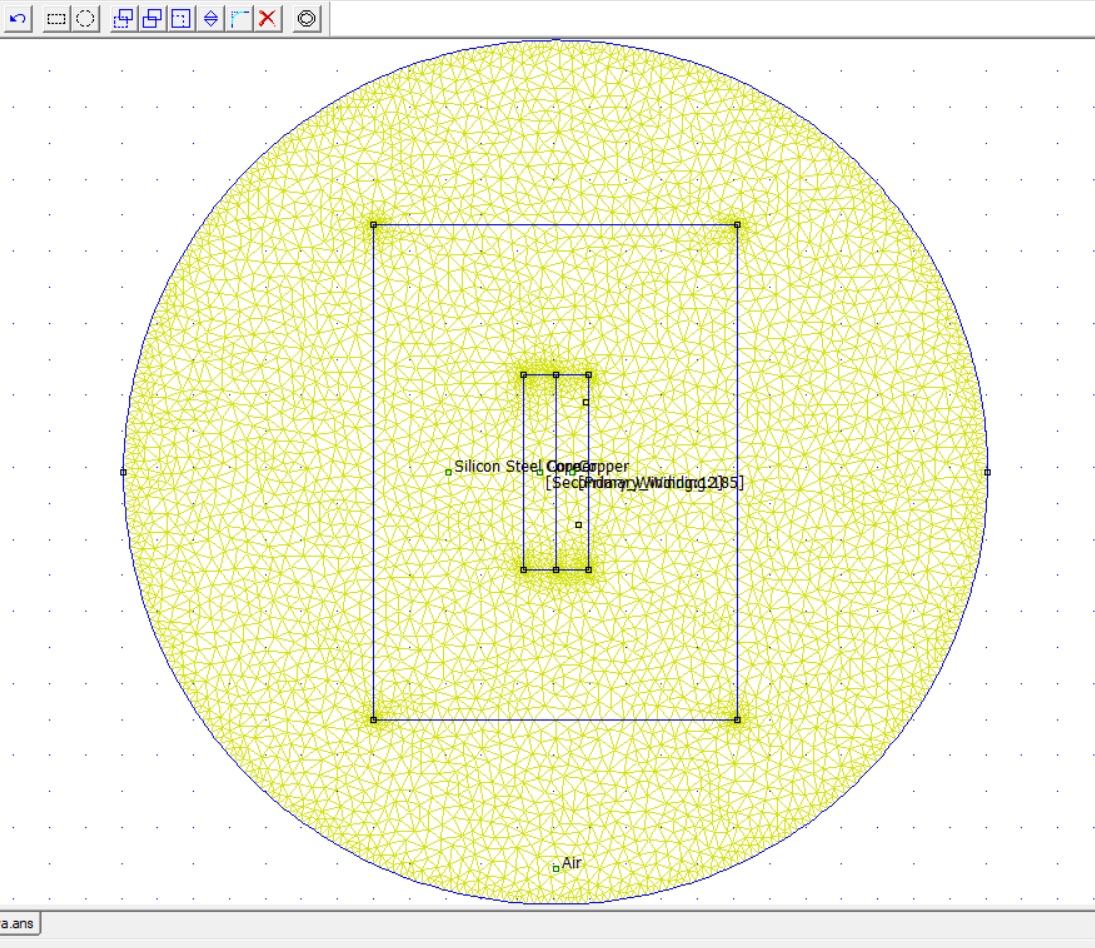

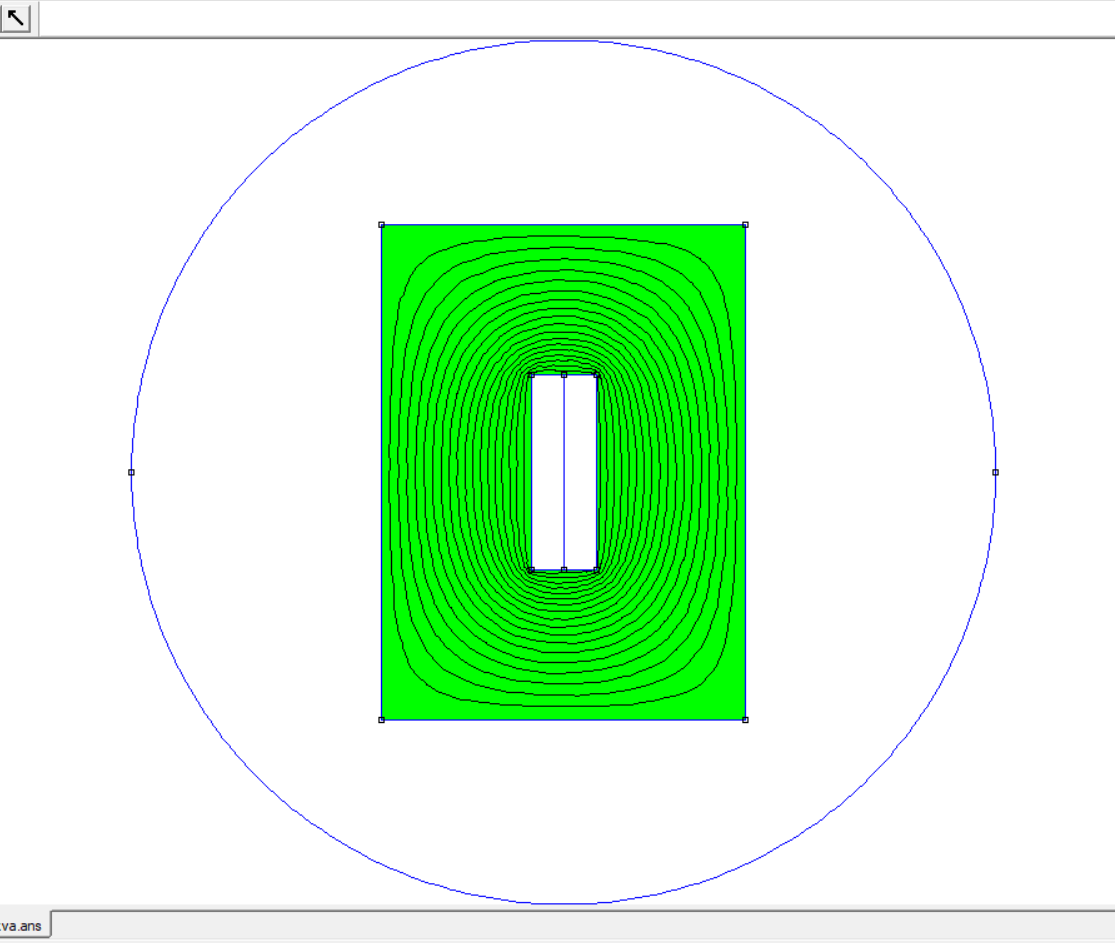

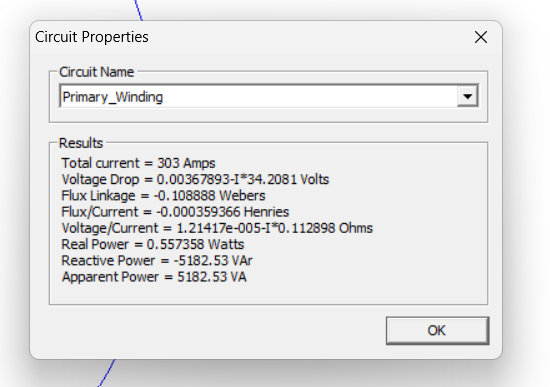

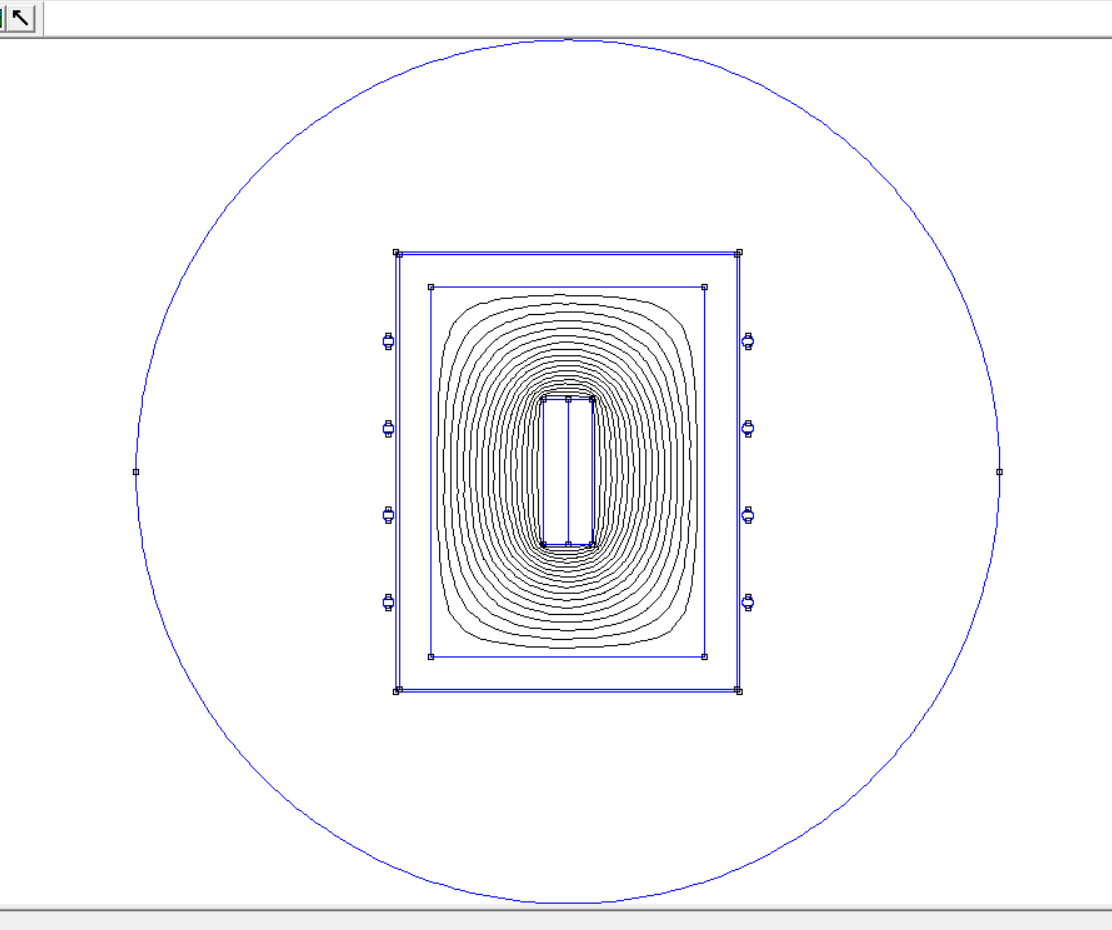

In [44]:
import os
from IPython.display import Image, display, HTML

# 1. Grab all 4 absolute paths cleanly
p1 = os.path.abspath("../img/Screenshot 2026-11-01 173326.png")
p2 = os.path.abspath("../img/Screenshot 2026-11-01 173344.png")
p3 = os.path.abspath("../img/Screenshot 2026-11-01 173512.png")
p4 = os.path.abspath("../img/Screenshot 2026-11-01 174055.png")

# 2. Tell Jupyter to display them inline side-by-side using minimal CSS styling
display(HTML("<style>.output_subarea { display: flex; flex-wrap: wrap; }</style>"))
display(Image(filename=p1, width=350), Image(filename=p2, width=350),
        Image(filename=p3, width=350), Image(filename=p4, width=350))